In [26]:
import numpy as np

class NaiveBayes:
  #dont need __init because we don't have parameters to configura
    def fit(self, X,y):
        n_samples, n_features = X.shape
        self._classes = np.unique(y)
        n_classes = len(self._classes)

        #calculate mean, var, and prior for each class
        self._mean = np.zeros((n_classes, n_features), dtype=np.float64)
        self._var = np.zeros((n_classes, n_features), dtype = np.float64)
        self._priors = np.zeros(n_classes, dtype=np.float64)

        for idx, c in enumerate(self._classes):
          X_c = X[y == c]
          self._mean[idx,:] = X_c.mean(axis=0)
          self._var[idx,:] = X_c.var(axis=0)
          self._priors[idx] = X_c.shape[0] / float(n_samples)

    def predict(self,X):

        y_pred = [self._predict(x) for x in X]
        return np.array(y_pred)

    def _predict(self, x):
        posteriors = []
        for idx, c in enumerate(self._classes):

            prior = np.log(self._priors[idx])
            posterior = np.sum(np.log(self._pdf(idx, x)))
            psoterior = posterior + prior
            posteriors.append(posterior)

        return self._classes[np.argmax(posteriors)]

    def _pdf(self, class_idx, x):
        mean = self._mean[class_idx]
        var = self._var[class_idx]
        numerator = np.exp(-((x-mean)**2)/(2*var))
        denominator = np.sqrt(2*np.pi*var)
        return numerator/denominator





#Trying the code:

In [28]:

from sklearn.model_selection import train_test_split
from sklearn import datasets

def accuracy(y_true, y_pred):
    accuracy = np.sum(y_true == y_pred) / len(y_true)
    return accuracy

#toy dataset
X,y=datasets.make_classification(
        n_samples=1000, n_features=10, n_classes=2, random_state=123
    )
#training and testing
X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=123
    )


nb=NaiveBayes()
nb.fit(X_train, y_train)
predictions=nb.predict(X_test)

print("Naive Bayes Classification Acuracy:", accuracy(y_test, predictions))


Naive Bayes Classification Acuracy: 0.965


We'll add the Iris dataset, which is a well-known classification problem with 3 classes (versus the binary classification in your synthetic dataset). We can visualize the feature distributions and show how well Naive Bayes performs on this dataset.

In [30]:
# Dataset 2: Iris Dataset (Built-in Dataset)
iris = datasets.load_iris()
X_iris, y_iris = iris.data, iris.target

# Split dataset into training and testing
X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris, y_iris, test_size=0.2, random_state=123
)

# Train Naive Bayes on Iris dataset
nb.fit(X_train_iris, y_train_iris)
predictions_iris = nb.predict(X_test_iris)

# Calculate accuracy
accuracy_iris = accuracy(y_test_iris, predictions_iris)
print(f"Naive Bayes Accuracy on Iris Dataset: {accuracy_iris:.4f}")



Naive Bayes Accuracy on Iris Dataset: 0.9667


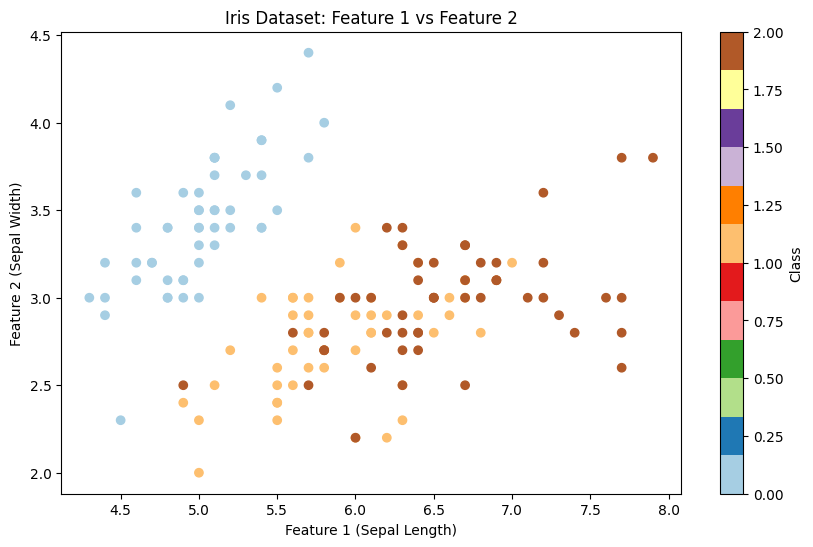

In [32]:
# Visualizations (for Iris Dataset)
# Plot the first two features to see the separation
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.scatter(X_iris[:, 0], X_iris[:, 1], c=y_iris, cmap=plt.cm.Paired)
plt.title("Iris Dataset: Feature 1 vs Feature 2")
plt.xlabel("Feature 1 (Sepal Length)")
plt.ylabel("Feature 2 (Sepal Width)")
plt.colorbar(label="Class")
plt.show()

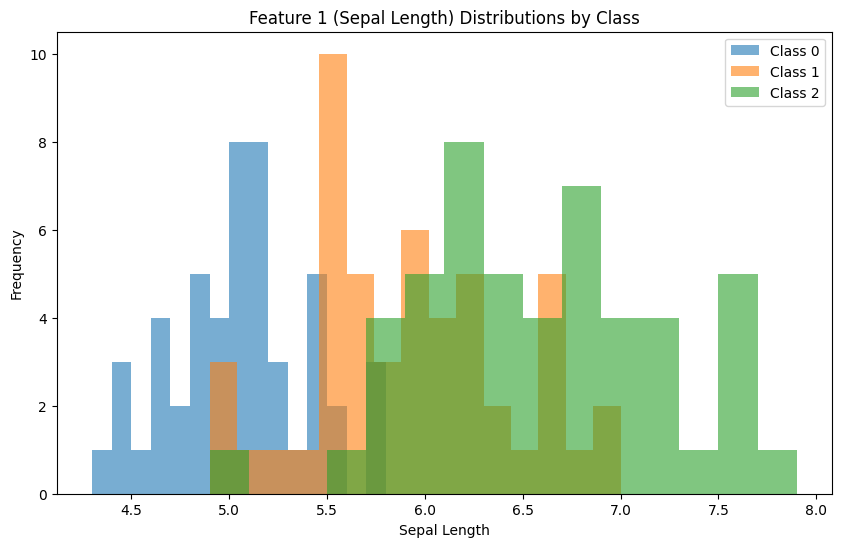

In [33]:
# Plot the distributions of the first feature for each class in Iris dataset
plt.figure(figsize=(10, 6))
for i in range(3):
    plt.hist(X_iris[y_iris == i, 0], bins=15, alpha=0.6, label=f"Class {i}")
plt.title("Feature 1 (Sepal Length) Distributions by Class")
plt.xlabel("Sepal Length")
plt.ylabel("Frequency")
plt.legend()
plt.show()
